# โมเดลที่ 2 — เลือกแถวแล้วดูว่าโมเดลทายอะไร เพราะอะไร

**วิธีใช้**
1. วาง `features_ready_2.csv` ไว้โฟลเดอร์เดียวกับ notebook
2. กด **Run All**
3. เลื่อนลงไปล่างสุด เลือกแถวจาก dropdown → ดูผลทาย + เหตุผลว่าทำไมทายแบบนั้น

**ตอนนี้ไม่มีไฟล์ test** notebook จะเลือกโหมดให้อัตโนมัติ:

| สถานการณ์ | โมเดลเทรนจาก | แถวที่เลือกดูได้ |
|---|---|---|
| **ไม่มี test (ตอนนี้)** | 70% แรกของแต่ละคน/กิจกรรม | 30% หลัง (validation) ซึ่งโมเดลไม่เคยเห็น |
| ไฟล์มีคอลัมน์ `split` ที่มีค่า `test` | แถว train | แถว test |
| ได้ไฟล์ test แยกมา → ใส่ชื่อใน `TEST_PATH` | ไฟล์ `DATA_PATH` ทั้งไฟล์ | แถวในไฟล์ test |

ทำไมไม่ให้เลือกดูแถวที่ใช้เทรนไปเลย: ถ้าเลือกแถวที่โมเดลเคยเห็นแล้ว ก็เหมือนเอาข้อสอบที่ใช้ติวมาสอบ ผลถูกหรือผิดที่เห็นจะไม่ได้บอกว่าโมเดลเก่งจริงแค่ไหน

**ไฟล์ต้องมี:** 24 คอลัมน์ฟีเจอร์ (ปรับสเกลแล้ว) ชื่อ `ax_mean … gz_max`
- ไฟล์ train ต้องมีคอลัมน์ `activity` (เฉลย) ด้วย
- ไฟล์ test จะมี `activity` หรือไม่มีก็ได้ ถ้ามีจะบอกว่าทายถูกไหม ถ้าไม่มีจะบอกแค่ผลทาย

In [3]:
# ===== แก้ตรงนี้ถ้าชื่อไฟล์ไม่ตรง =====
DATA_PATH    = "features_ready_2.csv"   # ไฟล์ข้อมูลที่ใช้เทรน
TEST_PATH    = None                     # ได้ไฟล์ test มาเมื่อไหร่ ใส่ชื่อไฟล์ตรงนี้ เช่น "test.csv"
HOLDOUT_FRAC = 0.30                     # โหมดไม่มี test: กันหน้าต่าง 30% หลังของแต่ละคน/กิจกรรมไว้เป็น validation
# =====================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML

np.set_printoptions(precision=4, suppress=True)

FEATURE_COLS = [f"{ch}_{st}"
                for ch in ["ax", "ay", "az", "gx", "gy", "gz"]
                for st in ["mean", "std", "min", "max"]]

## 1. โหลดและตรวจไฟล์

ตรวจให้ครบก่อนเทรน: มีคอลัมน์ครบไหม, มีค่าว่างไหม — ถ้าผิดจะหยุดพร้อมบอกว่าผิดตรงไหน ดีกว่าปล่อยให้โมเดลทายมั่วแบบเงียบๆ

In [4]:
def load_and_check(path, need_label):
    df = pd.read_csv(path)
    missing = [c for c in FEATURE_COLS if c not in df.columns]
    if missing:
        raise ValueError(f"{path}: ขาดคอลัมน์ {missing}")
    if need_label and "activity" not in df.columns:
        raise ValueError(f"{path}: ไฟล์ train ต้องมีคอลัมน์ activity")
    n_nan = df[FEATURE_COLS].isna().sum().sum()
    if n_nan:
        raise ValueError(f"{path}: มีค่าว่าง {n_nan} ช่อง")
    return df.reset_index(drop=True)

all_df = load_and_check(DATA_PATH, need_label=True)

if TEST_PATH:                                                   # โหมด 3: มีไฟล์ test แยก
    MODE = "test file"
    train_df = all_df
    test_df  = load_and_check(TEST_PATH, need_label=False)
elif "split" in all_df.columns and (all_df["split"] == "test").any():   # โหมด 2: split อยู่ในไฟล์
    MODE = "split column"
    train_df = all_df[all_df["split"] == "train"].reset_index(drop=True)
    test_df  = all_df[all_df["split"] == "test"].reset_index(drop=True)
else:                                                            # โหมด 1: ไม่มี test → time hold-out
    MODE = "validation (no test file)"
    grp = ["subject", "activity"] if "subject" in all_df.columns else ["activity"]
    pos  = all_df.groupby(grp).cumcount()                        # ลำดับหน้าต่างตามเวลาในแต่ละกลุ่ม
    size = all_df.groupby(grp)["activity"].transform("size")
    is_val = pos >= (size * (1 - HOLDOUT_FRAC)).round()          # หน้าต่างช่วงท้าย = validation
    train_df = all_df[~is_val].reset_index(drop=True)
    test_df  = all_df[is_val].reset_index(drop=True)
print("โหมด:", MODE)
HAS_SUBJECT = "subject" in test_df.columns
s_test = test_df["subject"].to_numpy(dtype=str) if HAS_SUBJECT else None
HAS_LABEL = "activity" in test_df.columns

X_train = train_df[FEATURE_COLS].to_numpy()          # ใช้ FEATURE_COLS เรียงคอลัมน์เสมอ
y_train = train_df["activity"].to_numpy(dtype=str)   # ต่อให้ในไฟล์สลับลำดับมาก็ไม่เป็นไร
X_test  = test_df[FEATURE_COLS].to_numpy()
y_test  = test_df["activity"].to_numpy(dtype=str) if HAS_LABEL else None

print(f"เทรน: {X_train.shape[0]} แถว | แถวให้เลือกดู: {X_test.shape[0]} แถว | มีเฉลย: {HAS_LABEL}")
print("\nจำนวนแถวต่อกิจกรรมใน train:")
print(train_df["activity"].value_counts().sort_index().to_string())
if HAS_LABEL:
    unseen = set(y_test) - set(y_train)
    if unseen:
        print("\n⚠️ test มีกิจกรรมที่ train ไม่มี (โมเดลทายถูกไม่ได้แน่นอน):", unseen)

โหมด: validation (no test file)
เทรน: 744 แถว | แถวให้เลือกดู: 336 แถว | มีเฉลย: True

จำนวนแถวต่อกิจกรรมใน train:
activity
downstairs     124
laying_left    124
sitting        124
standing       124
upstairs       124
walking        124


## 2. เทรนโมเดล (ใช้ไฟล์ train อย่างเดียว)

ขั้นเดียวกับ notebook แรก รวบไว้ในฟังก์ชันเดียว:
μ → ลบ μ → covariance → eigen (เรียงมาก→น้อย)

eigen คำนวณ**ครั้งเดียว** ส่วนการเลือก k แค่หยิบ eigenvector k คอลัมน์แรก เลยเปลี่ยน k ในหน้าจอได้ทันทีไม่ต้องเทรนใหม่

In [5]:
def fit_pca(X):
    mu = X.mean(axis=0)
    Xc = X - mu
    cov = Xc.T @ Xc / (len(X) - 1)
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]          # eigh เรียงน้อย→มาก ต้องกลับ
    return mu, vals[order], vecs[:, order]

def build_model(k):
    """ใช้ μ/eigenvector ที่คำนวณแล้ว หยิบ k ทิศ แล้วหา centroid"""
    W = eigvecs[:, :k]
    Z = (X_train - mu) @ W
    cents = np.array([Z[y_train == c].mean(axis=0) for c in classes])
    return W, Z, cents

def project(X, W):
    return (np.atleast_2d(X) - mu) @ W

def distances(Z, cents):
    # ระยะ Euclidean จากทุกจุดไปทุก centroid → shape (n, จำนวนกิจกรรม)
    return np.linalg.norm(Z[:, None, :] - cents[None, :, :], axis=2)

mu, eigvals, eigvecs = fit_pca(X_train)
classes = np.unique(y_train)
cumulative = np.cumsum(eigvals) / eigvals.sum()

import os
if os.path.exists("model2.npz"):                       # ใช้ k ที่เลือกไว้ใน model2_pca.ipynb (ด้วย validation)
    DEFAULT_K = int(np.load("model2.npz")["k"])
    src = "จาก model2.npz (เลือกด้วย validation ใน model2_pca.ipynb)"
else:
    DEFAULT_K = int(np.argmax(cumulative >= 0.90) + 1)
    src = "เกณฑ์ความกระจายสะสม ≥ 90% (ยังไม่มี model2.npz — รัน model2_pca.ipynb ก่อนจะได้ k ที่ดีกว่า)"
print(f"k เริ่มต้น = {DEFAULT_K}  ← {src}")
print(f"k = {DEFAULT_K} เก็บความกระจาย {cumulative[DEFAULT_K-1]*100:.1f}%")
print("% สะสม 6 ทิศแรก:", (cumulative[:6] * 100).round(1))

k เริ่มต้น = 7  ← จาก model2.npz (เลือกด้วย validation ใน model2_pca.ipynb)
k = 7 เก็บความกระจาย 96.7%
% สะสม 6 ทิศแรก: [63.7 77.8 89.3 92.2 94.4 95.8]


## 3. ฟังก์ชันอธิบายผลของแถวที่เลือก

ทำตามขั้น 5 ของโมเดลจิ๋ว แล้ว **โชว์ทุกขั้นกลาง** ให้เห็นว่าโมเดลคิดยังไง:
① ค่า 24 ฟีเจอร์ของแถวนั้น → ② ลบ μ แล้วฉาย ได้พิกัด z (k ตัว) → ③ ระยะไปแต่ละ centroid → ④ เลือกตัวที่ใกล้สุด

In [6]:
COLORS = dict(zip(classes, plt.cm.tab10.colors))

def explain_row(row, k):
    W, Z_train, cents = build_model(k)
    x = X_test[row]
    z = project(x, W)[0]
    d = distances(z[None, :], cents)[0]
    pred = classes[np.argmin(d)]

    # ---------- หัวข้อผลลัพธ์ ----------
    if HAS_LABEL:
        actual = y_test[row]
        ok = pred == actual
        verdict = (f"<span style='color:{'green' if ok else 'crimson'}'>"
                   f"{'✅ ถูก' if ok else '❌ ผิด'}</span> (เฉลย: <b>{actual}</b>)")
    else:
        verdict = "(ไฟล์ test ไม่มีเฉลย)"
    display(HTML(f"<h3>แถว {row} → โมเดลทายว่า <b>{pred}</b> {verdict}</h3>"))

    # ---------- ตารางระยะ ----------
    dist_tbl = (pd.DataFrame({"ระยะไป centroid": d.round(3)}, index=classes)
                  .sort_values("ระยะไป centroid"))
    dist_tbl["ห่างจากอันดับ 1"] = (dist_tbl.iloc[:, 0] - dist_tbl.iloc[0, 0]).round(3)
    z_tbl = pd.DataFrame([z.round(3)], columns=[f"PC{i+1}" for i in range(k)], index=["z ของแถวนี้"])
    display(HTML("<b>② พิกัดหลังฉาย (k ตัวเลข)</b>")); display(z_tbl)
    display(HTML("<b>③ ระยะไปแต่ละ centroid (น้อย = ใกล้ = คล้าย)</b>")); display(dist_tbl)

    gap = dist_tbl.iloc[1, 0] - dist_tbl.iloc[0, 0]
    if gap < 0.3:
        display(HTML(f"<i>⚠️ อันดับ 1 กับ 2 ห่างกันแค่ {gap:.3f} — โมเดลไม่ค่อยมั่นใจ "
                     f"({dist_tbl.index[0]} vs {dist_tbl.index[1]})</i>"))

    # ---------- กราฟ ----------
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6),
                             gridspec_kw={"width_ratios": [1.2, 1, 1.4]})

    # (ก) แผนที่ PC1–PC2
    ax = axes[0]
    for c in classes:
        m = y_train == c
        ax.scatter(Z_train[m, 0], Z_train[m, 1] if k > 1 else np.zeros(m.sum()),
                   s=12, alpha=0.35, color=COLORS[c], label=c)
        cy = cents[classes == c][0]
        ax.scatter(cy[0], cy[1] if k > 1 else 0, s=160, marker="X",
                   color=COLORS[c], edgecolor="black")
    ax.scatter(z[0], z[1] if k > 1 else 0, s=380, marker="*", color="gold",
               edgecolor="black", zorder=5, label="this row")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2" if k > 1 else "")
    ax.set_title("Train points, centroids (X) and this row (*)\n(shows only PC1-PC2)")
    ax.legend(fontsize=7, loc="best")

    # (ข) ระยะไปแต่ละ centroid
    ax = axes[1]
    srt = dist_tbl.index.tolist()
    ax.barh(srt[::-1], dist_tbl.iloc[:, 0].values[::-1],
            color=[COLORS[c] for c in srt[::-1]], edgecolor="black")
    ax.set_xlabel("distance (smaller = closer)"); ax.set_title(f"Distance to centroids (k = {k})")

    # (ค) ค่า 24 ฟีเจอร์ เทียบกับค่าเฉลี่ยของกิจกรรมที่ทาย
    ax = axes[2]
    pos = np.arange(24)
    ax.bar(pos - 0.2, x, width=0.4, label="this row", color="gold", edgecolor="black")
    ax.bar(pos + 0.2, X_train[y_train == pred].mean(axis=0), width=0.4,
           label=f"avg of '{pred}' in train", color=COLORS[pred], alpha=0.7)
    ax.set_xticks(pos); ax.set_xticklabels(FEATURE_COLS, rotation=90, fontsize=7)
    ax.axhline(0, color="gray", lw=0.6); ax.legend(fontsize=8)
    ax.set_title("① 24 features (scaled)")
    plt.tight_layout(); plt.show()

def test_accuracy(k):
    W, _, cents = build_model(k)
    pred = classes[np.argmin(distances(project(X_test, W), cents), axis=1)]
    return pred, ((pred == y_test).mean() if HAS_LABEL else None)

## 4. 🖥️ หน้าจอเลือกแถว

- **คน**: ดูเฉพาะข้อมูลของคนใดคนหนึ่ง (ถ้าไฟล์มีคอลัมน์ subject)
- **แสดง**: ทุกแถว / เฉพาะที่ทายผิด / เฉพาะกิจกรรมใดกิจกรรมหนึ่ง (ตัวกรองเกี่ยวกับเฉลยใช้ได้เมื่อ test มีคอลัมน์ activity)
- **แถว**: เลือกแถวที่อยากดู (ในวงเล็บคือเฉลย / ผลทาย)
- **k**: จำนวนทิศ PCA ที่เก็บไว้ ลองเลื่อนดูว่าผลเปลี่ยนยังไง

⚠️ ถ้าหน้าจอไม่ขึ้น ให้ติดตั้งก่อน: `pip install ipywidgets` แล้ว restart kernel

In [7]:
k_slider = widgets.IntSlider(value=DEFAULT_K, min=1, max=24, description="k:",
                             continuous_update=False, layout=widgets.Layout(width="420px"))
filter_opts = ["ทุกแถว"] + (["เฉพาะที่ทายผิด"] + [f"กิจกรรม: {c}" for c in np.unique(y_test)]
                            if HAS_LABEL else [])
filter_dd = widgets.Dropdown(options=filter_opts, description="แสดง:",
                             layout=widgets.Layout(width="320px"))
subj_dd = widgets.Dropdown(options=["ทุกคน"] + (list(np.unique(s_test)) if HAS_SUBJECT else []),
                           description="คน:", layout=widgets.Layout(width="220px"))
row_dd = widgets.Dropdown(description="แถว:", layout=widgets.Layout(width="420px"))
prev_btn = widgets.Button(description="◀ ก่อนหน้า", layout=widgets.Layout(width="110px"))
next_btn = widgets.Button(description="ถัดไป ▶", layout=widgets.Layout(width="110px"))
summary = widgets.HTML()
out = widgets.Output()

def refresh_rows(*_):
    k = k_slider.value
    pred, acc = test_accuracy(k)
    idx = np.arange(len(X_test))
    if subj_dd.value != "ทุกคน":
        idx = idx[s_test[idx] == subj_dd.value]
    f = filter_dd.value
    if f == "เฉพาะที่ทายผิด":
        idx = idx[pred[idx] != y_test[idx]]
    elif f.startswith("กิจกรรม: "):
        idx = idx[y_test[idx] == f.split(": ", 1)[1]]

    def label(i):
        who = f"[{s_test[i]}] " if HAS_SUBJECT else ""
        if HAS_LABEL:
            mark = "✅" if pred[i] == y_test[i] else "❌"
            return f"{i:>4} {who}{mark} จริง: {y_test[i]}  | ทาย: {pred[i]}"
        return f"{i:>4} {who}ทาย: {pred[i]}"

    old = row_dd.value
    row_dd.options = [(label(i), int(i)) for i in idx] or [("— ไม่มีแถวที่ตรงเงื่อนไข —", -1)]
    row_dd.value = old if old in idx else row_dd.options[0][1]

    acc_txt = (f"ความแม่นบน{' validation' if MODE.startswith('validation') else ' test'} ทั้งหมด = <b>{acc*100:.1f}%</b> "
               f"({int((pred == y_test).sum())}/{len(y_test)})" if HAS_LABEL else "test ไม่มีเฉลย")
    if HAS_LABEL and HAS_SUBJECT and subj_dd.value != "ทุกคน":
        sm = s_test == subj_dd.value
        acc_txt += (f" &nbsp;|&nbsp; เฉพาะ {subj_dd.value} = "
                    f"<b>{(pred[sm] == y_test[sm]).mean()*100:.1f}%</b>")
    summary.value = (f"k = {k} เก็บความกระจาย <b>{cumulative[k-1]*100:.1f}%</b> &nbsp;|&nbsp; "
                     f"{acc_txt} &nbsp;|&nbsp; กำลังแสดง {len(idx)} แถว")

def redraw(*_):
    out.clear_output(wait=True)
    with out:
        if row_dd.value is not None and row_dd.value >= 0:
            explain_row(row_dd.value, k_slider.value)

def step(delta):
    vals = [v for _, v in row_dd.options]
    if row_dd.value in vals:
        row_dd.value = vals[(vals.index(row_dd.value) + delta) % len(vals)]

prev_btn.on_click(lambda _: step(-1))
next_btn.on_click(lambda _: step(+1))
k_slider.observe(lambda ch: (refresh_rows(), redraw()), names="value")
filter_dd.observe(lambda ch: (refresh_rows(), redraw()), names="value")
subj_dd.observe(lambda ch: (refresh_rows(), redraw()), names="value")
row_dd.observe(redraw, names="value")

refresh_rows(); redraw()
display(widgets.VBox([
    widgets.HBox([subj_dd, filter_dd, k_slider]),
    widgets.HBox([row_dd, prev_btn, next_btn]),
    summary, out,
]))

## 5. (สำรอง) ดูแถวเดียวโดยไม่ใช้หน้าจอ

ถ้าเครื่องไหนเปิด widget ไม่ได้ (เช่นบางเวอร์ชันของ VS Code / Colab) ใช้ cell นี้แทน แก้เลขแถวกับ k แล้วรัน

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
z ของแถวนี้,0.241,0.435,-0.221,-0.391,-0.177,-0.175,-0.188


,ระยะไป centroid,ห่างจากอันดับ 1
downstairs,1.379,0.000
walking,1.845,0.466
upstairs,1.888,0.509
standing,1.900,0.521
laying_left,2.579,1.200
sitting,3.002,1.623


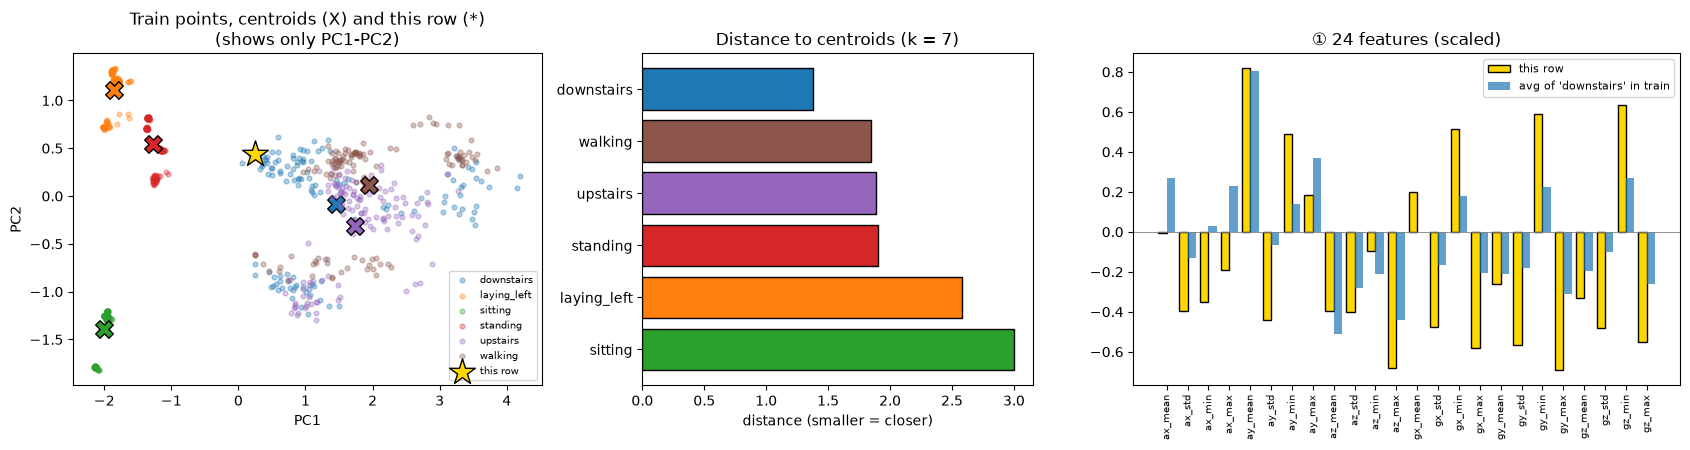

In [8]:
explain_row(row=0, k=DEFAULT_K)

## 6. ผลรวมทั้งไฟล์ test (ถ้ามีเฉลย)

แถว = คำตอบจริง, คอลัมน์ = ที่โมเดลทาย ตัวเลขนอกแนวทแยงคือคู่ที่โมเดลสับสน

In [9]:
if HAS_LABEL:
    pred_all, acc = test_accuracy(DEFAULT_K)
    print(f"k = {DEFAULT_K}: accuracy = {acc*100:.2f}%")
    cm = pd.crosstab(pd.Series(y_test, name="จริง"), pd.Series(pred_all, name="ทาย"))
    display(cm)
    if HAS_SUBJECT:
        print("\nความแม่นแยกตามคน:")
        for s in np.unique(s_test):
            m = s_test == s
            print(f"  {s:<8} {(pred_all[m] == y_test[m]).mean()*100:5.1f}%")
else:
    print("test ไม่มีคอลัมน์ activity — วัดความแม่นไม่ได้")

k = 7: accuracy = 87.80%


ทาย,downstairs,laying_left,sitting,standing,upstairs,walking
จริง,,,,,,
downstairs,38,0,0,0,4,14
laying_left,0,56,0,0,0,0
sitting,0,0,56,0,0,0
standing,0,0,0,56,0,0
upstairs,1,0,0,0,54,1
walking,19,0,0,0,2,35



ความแม่นแยกตามคน:
  it        94.0%
  nick      89.3%
  ski       85.7%
  tonson    82.1%
